## Tourist-vessel coastal activity (Flag 23)

### Dataset Overview
Constructed tourist-vessel movements along the west-Jutland coast over one Monday-to-Sunday week: the nearshore majority follows coast-parallel excursion paths, while seven recurrent vessels make longer offshore trips connected to several coastal harbour areas.

The notebook exposes a primary table and a supporting table (`coastline_reference.csv`).

Goal: Analyze how tourist vessel movement patterns vary across time and different coastal operating areas.

Role: Maritime traffic analyst


Category: tourist-vessel coastal activity

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "coastline_reference.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: How does tourist-vessel activity vary between weekends and weekdays?

#### Analysis action

Compare average hourly departure counts and their earliest-to-latest windows on the left, while retaining the Monday-to-Sunday trajectory-count line on the right.

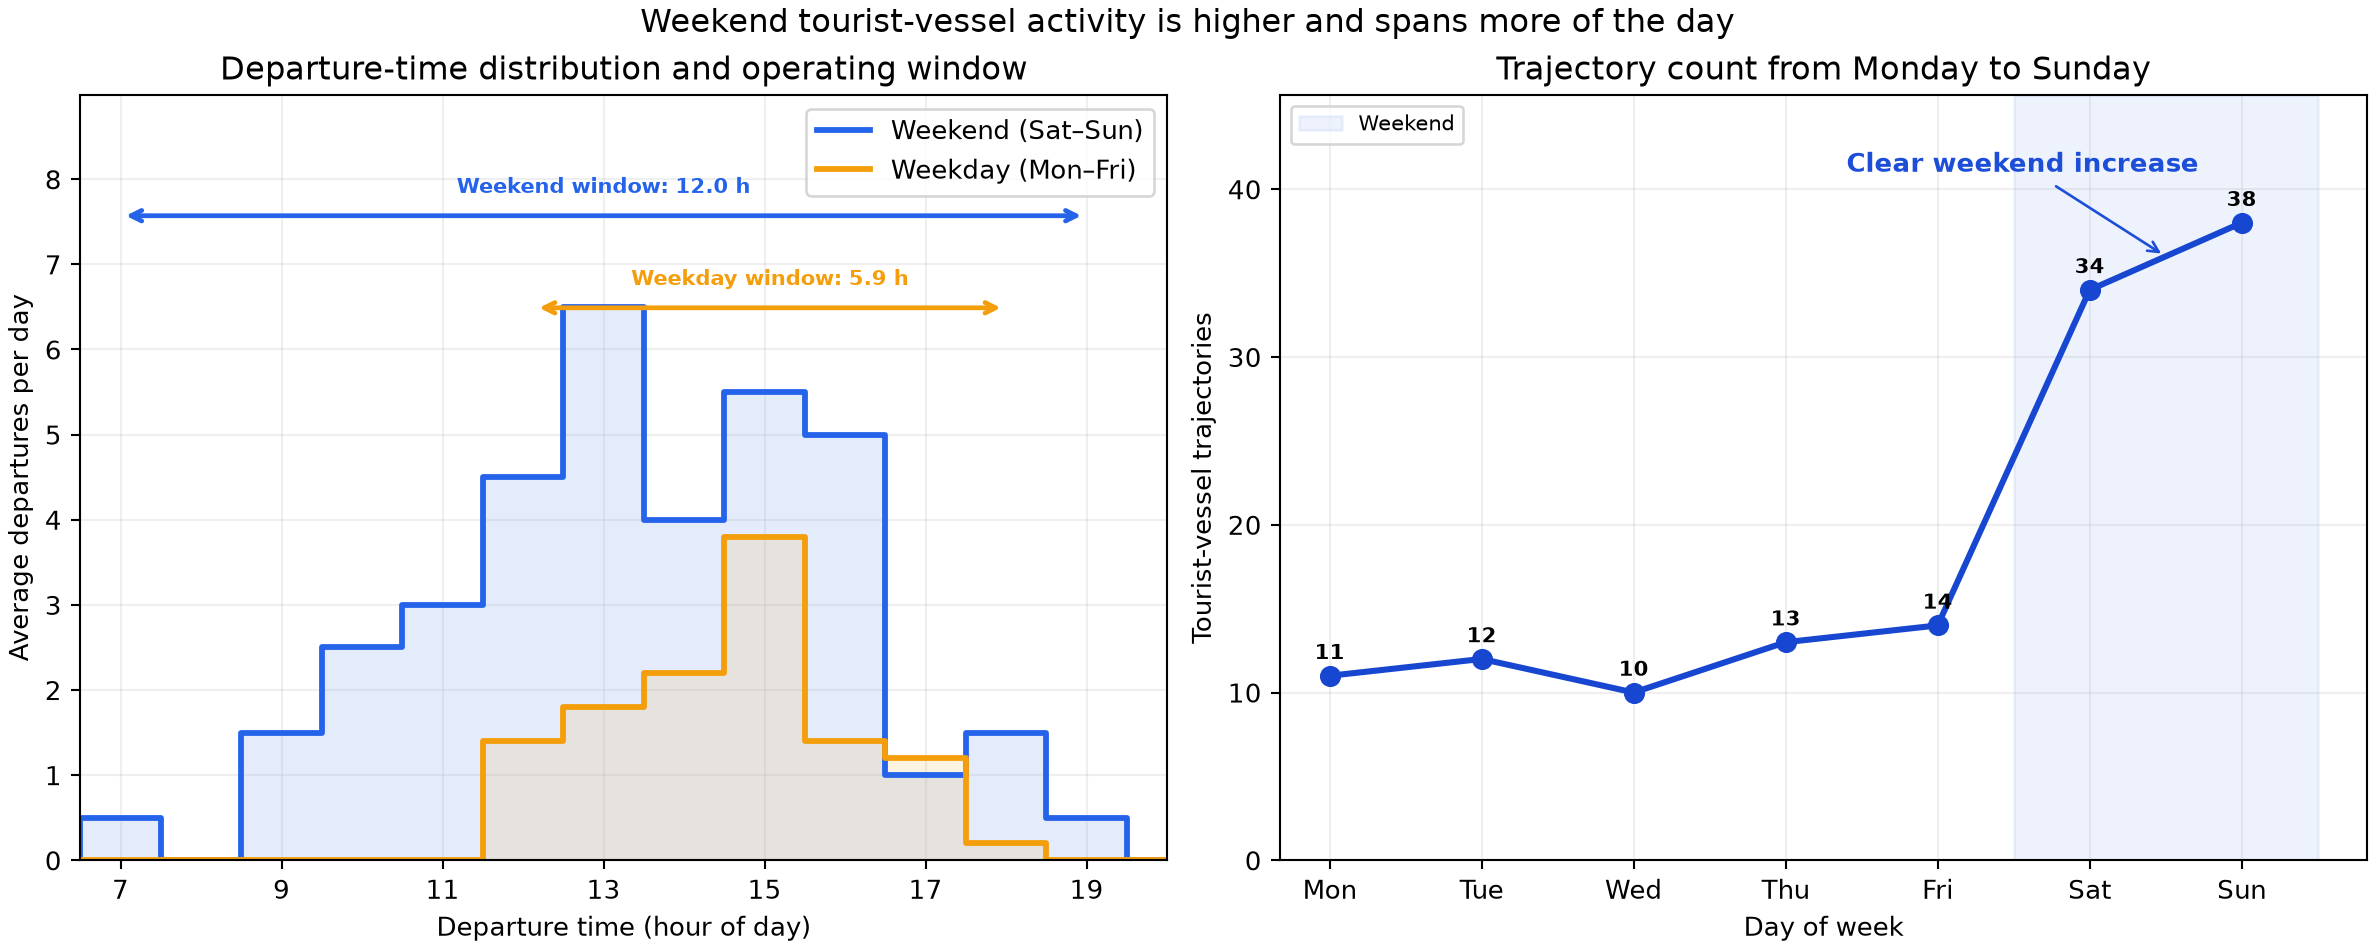

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); df['timestamp']=pd.to_datetime(df.timestamp); first=df.sort_values('point_index').groupby('trajectory_id').first(); first['start_hour']=first.timestamp.dt.hour+first.timestamp.dt.minute/60; print(first.groupby('day_type').start_hour.agg(['count','min','max']))
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/tourist_activity_by_time.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "tourist_weekend_activity",
  "insight": "Tourist vessel activity increases during weekend daytime periods, with departures spanning a wider portion of the day than on comparable weekdays.",
  "insight_value": {
    "trajectory_counts": {
      "weekend": 72,
      "weekday": 60
    },
    "daily_trajectory_counts": {
      "Monday": 11,
      "Tuesday": 12,
      "Wednesday": 10,
      "Thursday": 13,
      "Friday": 14,
      "Saturday": 34,
      "Sunday": 38
    },
    "mean_daily_trajectory_count": {
      "weekday": 12.0,
      "weekend": 36.0
    },
    "weekend_to_weekday_daily_activity_ratio": 3.0,
    "activity_hour_span": {
      "weekend": 12.0,
      "weekday": 5.9
    }
  },
  "plot": {
    "plot_type": "departure_time_distribution_and_day_of_week_counts",
    "title": "Tourist-vessel Activity by Time",
    "file": "visualizations/tourist_activity_by_time.png",
    "description": "Compare average hourly departure counts and their earliest-to-latest windows on the left, while retaining the Monday-to-Sunday trajectory-count line on the right."
  },
  "question": "How does tourist-vessel activity vary between weekends and weekdays?",
  "actionable_insight": "Compare average hourly departure counts and their earliest-to-latest windows on the left, while retaining the Monday-to-Sunday trajectory-count line on the right.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); df['timestamp']=pd.to_datetime(df.timestamp); first=df.sort_values('point_index').groupby('trajectory_id').first(); first['start_hour']=first.timestamp.dt.hour+first.timestamp.dt.minute/60; print(first.groupby('day_type').start_hour.agg(['count','min','max']))",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "trajectory_timestamp",
    "vessel_id"
  ]
}

### **Question 2**: Where do tourist vessels operate relative to the coast?

#### Analysis action

Show nearshore excursions following the west-Jutland coastline and a smaller recurrent group making structurally varied offshore trajectories from several coastal harbour areas.

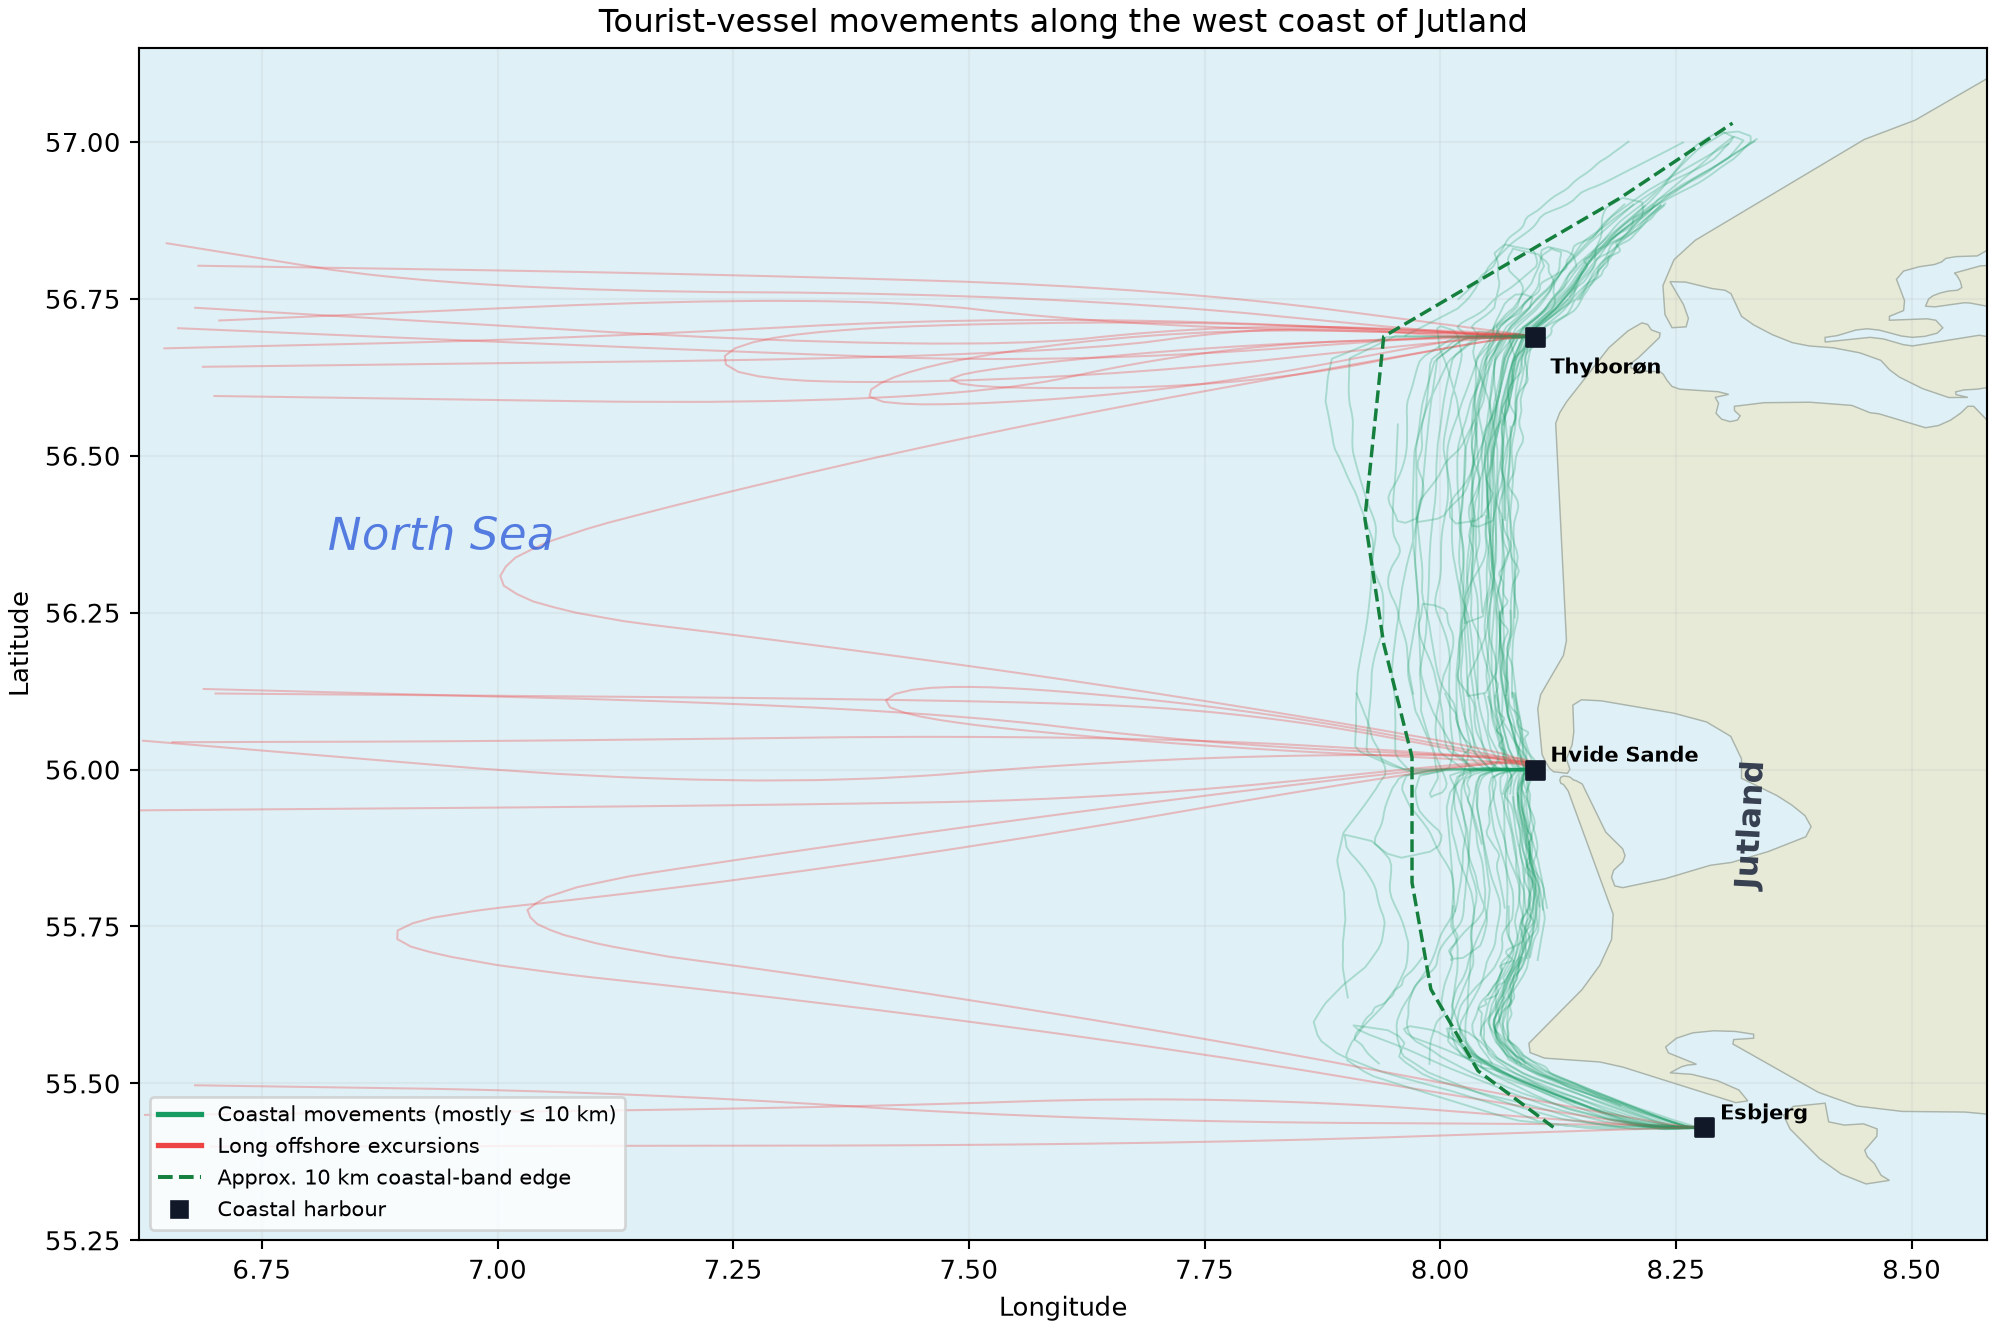

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); coast=pd.read_csv(user_dataset_path); print(df.groupby('operating_area').trajectory_id.nunique()); print(coast.head())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/coastal_offshore_tourist_routes.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "coastal_and_offshore_tourism",
  "insight": "Most tourist vessels remain close to the coastline, while a smaller recurring group makes longer offshore trips to and from coastal harbour areas.",
  "insight_value": {
    "operating_area_counts": {
      "nearshore": 109,
      "offshore": 23
    },
    "recurring_offshore_vessels": 7,
    "offshore_route_structure_counts": {
      "outbound offshore observation": 8,
      "inbound offshore observation": 8,
      "inter-harbour offshore transit": 3,
      "asymmetric harbour return": 2,
      "multi-leg offshore passage": 2
    },
    "median_coast_distance_km": {
      "nearshore": 3.66,
      "offshore": 43.38
    }
  },
  "plot": {
    "plot_type": "coast_following_and_offshore_route_map",
    "title": "Coastal and Offshore Tourist Routes",
    "file": "visualizations/coastal_offshore_tourist_routes.png",
    "description": "Show nearshore excursions following the west-Jutland coastline and a smaller recurrent group making structurally varied offshore trajectories from several coastal harbour areas."
  },
  "question": "Where do tourist vessels operate relative to the coast?",
  "actionable_insight": "Show nearshore excursions following the west-Jutland coastline and a smaller recurrent group making structurally varied offshore trajectories from several coastal harbour areas.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); coast=pd.read_csv(user_dataset_path); print(df.groupby('operating_area').trajectory_id.nunique()); print(coast.head())",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "ship_type",
    "gps_position",
    "coast_reference",
    "harbour_location",
    "trajectory_timestamp"
  ]
}

### **Question 3**: How is offshore distance associated with tourist-vessel movement behaviour?

#### Analysis action

Plot the continuous 0.1--100 km distance distribution with natural overlap between operating modes, then use separate trajectory-level boxplots for within-trajectory SOG variability and mean 15-minute COG change.

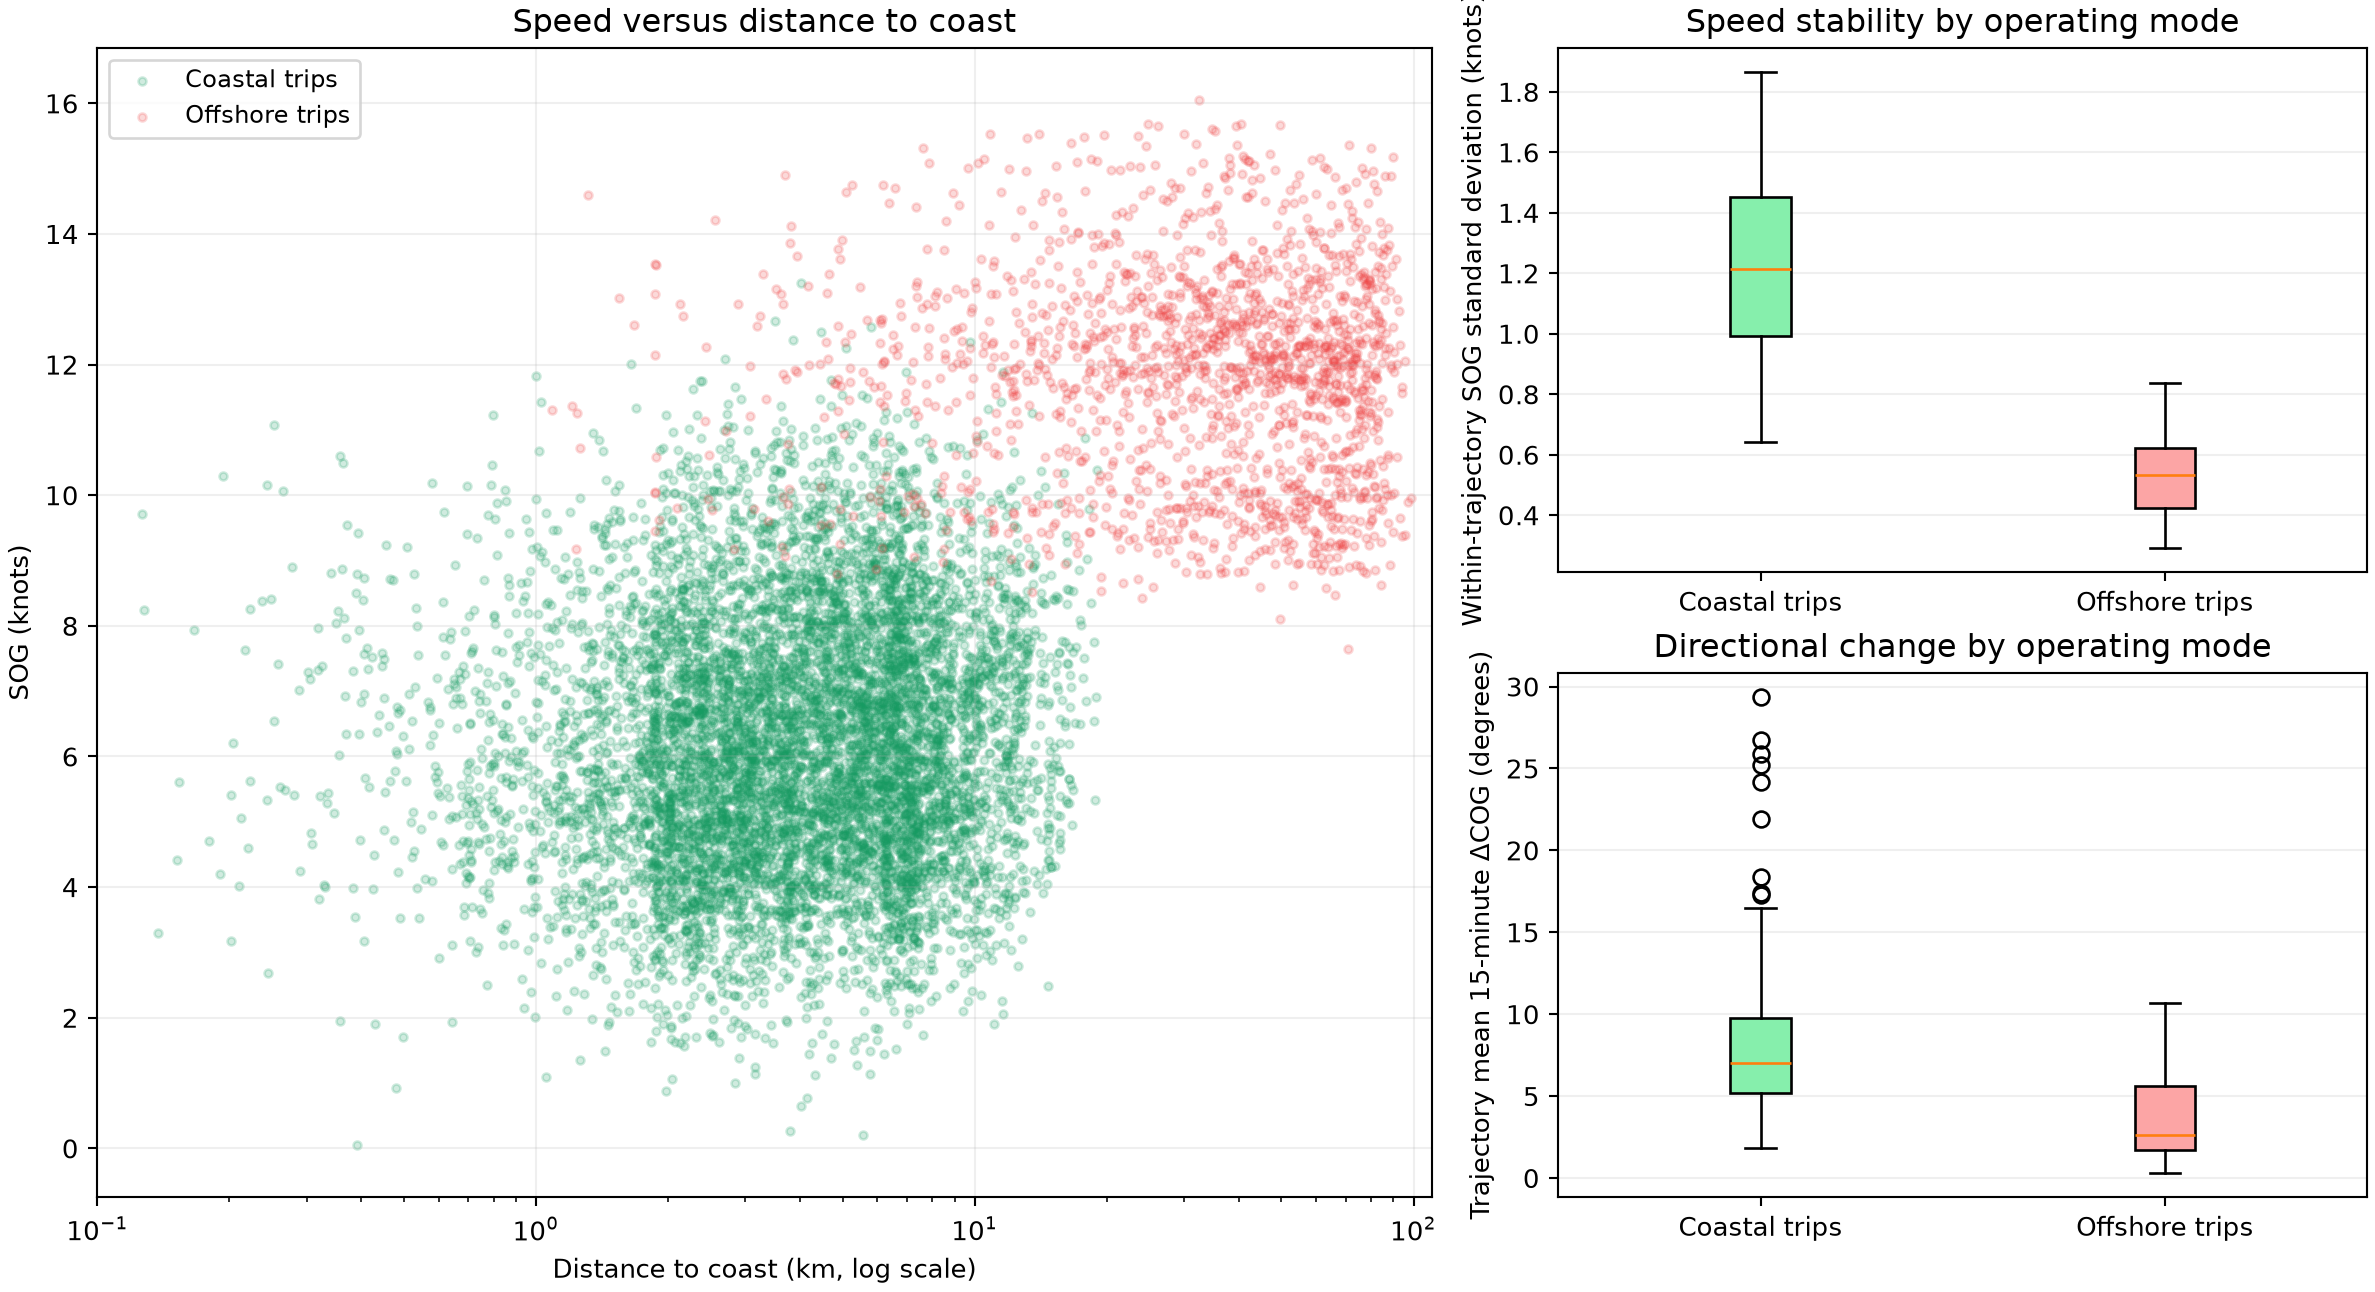

In [ ]:
import pandas as pd
df=pd.read_csv(dataset_path); x=df.query('distance_to_coast_km >= 0.10 and point_index >= 3').copy(); s=x.groupby(['trajectory_id','trajectory_coast_band']).agg(speed_sd_knots=('sog_knots','std'),mean_delta_cog_15min_deg=('delta_cog_15min_deg','mean')); print(s.groupby(level=1).median())
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/distance_speed_direction.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (7 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "offshore_speed_stability",
  "insight": "Farther-offshore trips generally maintain higher and more stable speeds, while nearshore movements show lower speeds and more frequent directional changes.",
  "insight_value": {
    "median_mean_speed_knots": {
      "nearshore": 6.25,
      "offshore": 11.95
    },
    "median_speed_sd_knots_by_coast_band": {
      "coastal": 1.21,
      "offshore": 0.53
    },
    "median_trajectory_mean_delta_cog_15min_deg_by_coast_band": {
      "coastal": 7.01,
      "offshore": 2.63
    }
  },
  "plot": {
    "plot_type": "distance_factor_comparison",
    "title": "Distance, Speed, and Directional Stability",
    "file": "visualizations/distance_speed_direction.png",
    "description": "Plot the continuous 0.1--100 km distance distribution with natural overlap between operating modes, then use separate trajectory-level boxplots for within-trajectory SOG variability and mean 15-minute COG change."
  },
  "question": "How is offshore distance associated with tourist-vessel movement behaviour?",
  "actionable_insight": "Plot the continuous 0.1--100 km distance distribution with natural overlap between operating modes, then use separate trajectory-level boxplots for within-trajectory SOG variability and mean 15-minute COG change.",
  "code": "import pandas as pd\ndf=pd.read_csv(dataset_path); x=df.query('distance_to_coast_km >= 0.10 and point_index >= 3').copy(); s=x.groupby(['trajectory_id','trajectory_coast_band']).agg(speed_sd_knots=('sog_knots','std'),mean_delta_cog_15min_deg=('delta_cog_15min_deg','mean')); print(s.groupby(level=1).median())",
  "insight_type": "factor_relationship",
  "difficulty_level": 7,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "ship_type",
    "gps_position",
    "coast_reference",
    "point_speed",
    "course_over_ground",
    "trajectory_timestamp",
    "vessel_id"
  ]
}

### Summary of Findings (Flag 23)

Tourist vessel activity increases during weekend daytime periods, with departures spanning a wider portion of the day than on comparable weekdays. Most tourist vessels remain close to the coastline, while a smaller recurring group makes longer offshore trips to and from coastal harbour areas. Farther-offshore trips generally maintain higher and more stable speeds, while nearshore movements show lower speeds and more frequent directional changes.